# Named Entity Recognition System
**CoNLL-2003 · LSTM vs BiLSTM vs BiLSTM+CRF (from scratch) vs fine-tuned DistilBERT · seqeval · Gradio**

Run on Colab with a GPU runtime (Runtime → Change runtime type → T4). Run all cells top to bottom.

Pipeline: explore data → IOB2 check → GloVe + char-CNN (OOV handling) → 3 scratch models (CRF written by hand) → HuggingFace token classification → seqeval per-entity evaluation → comparison and CRF boundary analysis → Gradio app.

> CoNLL-2003 has four entity types: PER, ORG, LOC, MISC. It has no DATE class, so dates are not tagged by the dataset; they usually fall into MISC or O.

In [1]:
!pip install -q datasets seqeval gensim "transformers>=4.46" accelerate gradio

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import random, time, json, re, collections
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from seqeval.metrics import classification_report, precision_score, recall_score, f1_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## 1. Load and explore CoNLL-2003

In [3]:
from datasets import load_dataset
# newer `datasets` versions cannot run dataset scripts, so load parquet copies of CoNLL-2003
for repo, kw in [("tomaarsen/conll2003", {}),
                 ("eriktks/conll2003", {"revision": "refs/convert/parquet"})]:
    try:
        ds = load_dataset(repo, **kw); print("Loaded:", repo); break
    except Exception as e:
        print(f"{repo} failed: {type(e).__name__}")
print(ds)
LABELS = ds["train"].features["ner_tags"].feature.names
L2I = {l: i for i, l in enumerate(LABELS)}
print(LABELS)

def to_tags(split):
    return [[LABELS[t] for t in tags] for tags in ds[split]["ner_tags"]]

data = {s: {"tokens": ds[s]["tokens"], "tags": to_tags(s)} for s in ["train", "validation", "test"]}

ex = 12
print(list(zip(data["train"]["tokens"][ex], data["train"]["tags"][ex])))

README.md:   0%|          | 0.00/15.0k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/13.5k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.24MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  316kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

Loaded: tomaarsen/conll2003
DatasetDict({
    train: Dataset({
        features: ['id', 'document_id', 'sentence_id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'document_id', 'sentence_id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'document_id', 'sentence_id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
[('Only', 'O'), ('France', 'B-LOC'), ('and', 'O'), ('Britain', 'B-LOC'), ('backed', 'O'), ('Fischler', 'B-PER'), ("'s", 'O'), ('proposal', 'O'), ('.', 'O')]


,split,sentences,tokens,avg_len,max_len
0,train,14041,203621,14.5,113
1,validation,3250,51362,15.8,109
2,test,3453,46435,13.4,124


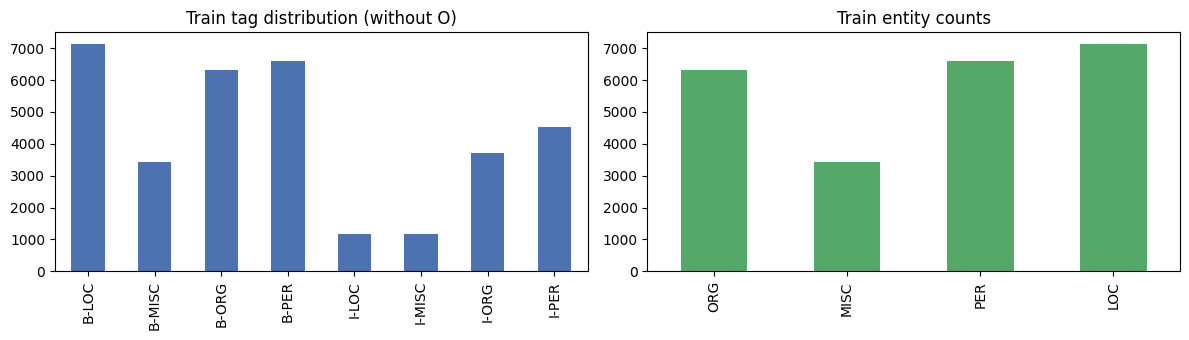

In [4]:
rows = []
for s in data:
    lens = [len(t) for t in data[s]["tokens"]]
    rows.append({"split": s, "sentences": len(lens), "tokens": sum(lens), "avg_len": round(np.mean(lens), 1), "max_len": max(lens)})
display(pd.DataFrame(rows))

cnt = collections.Counter(t for tags in data["train"]["tags"] for t in tags if t != "O")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
pd.Series(cnt).sort_index().plot.bar(ax=ax[0], color="#4C72B0", title="Train tag distribution (without O)")
ent = collections.Counter(t[2:] for t in cnt.elements() if t.startswith("B-"))
pd.Series(ent).plot.bar(ax=ax[1], color="#55A868", title="Train entity counts"); plt.tight_layout(); plt.show()

## 2. IOB tagging scheme
The dataset is already in **IOB2**: every entity starts with `B-TYPE`, continues with `I-TYPE`, and everything else is `O`. The check below verifies that no `I-X` tag appears without a preceding `B-X`/`I-X` (a boundary violation). We reuse it later to measure how often each model breaks the scheme.

In [5]:
def count_invalid(seqs):
    """Number of I-X tags not preceded by B-X or I-X (invalid IOB2 transitions)."""
    bad = 0
    for seq in seqs:
        prev = "O"
        for t in seq:
            if t.startswith("I-") and prev[2:] != t[2:] :
                bad += 1
            prev = t
    return bad

print("Invalid transitions in gold train tags:", count_invalid(data["train"]["tags"]))

Invalid transitions in gold train tags: 0


## 3. Embeddings and OOV handling
* **Word level:** pre-trained **GloVe 100d** (lower-cased words).
* **OOV / casing:** a **character-level CNN** over each word's characters, concatenated with the word vector. It captures capitalization, suffixes and shapes, so unseen words such as names still get useful features.

In [6]:
import gensim.downloader as api
glove = api.load("glove-wiki-gigaword-100")
EMB_DIM = glove.vector_size

PAD, UNK = "<pad>", "<unk>"
all_words = {w.lower() for s in data for sent in data[s]["tokens"] for w in sent}
words = [w for w in sorted(all_words) if w in glove.key_to_index]
w2i = {PAD: 0, UNK: 1, **{w: i + 2 for i, w in enumerate(words)}}

emb = np.random.normal(0, 0.1, (len(w2i), EMB_DIM)).astype("float32")
emb[0] = 0
for w, i in w2i.items():
    if w in glove.key_to_index: emb[i] = glove[w]
emb = torch.tensor(emb)

train_chars = collections.Counter(c for sent in data["train"]["tokens"] for w in sent for c in w)
c2i = {PAD: 0, UNK: 1, **{c: i + 2 for i, c in enumerate(sorted(train_chars))}}

all_train = [w.lower() for sent in data["train"]["tokens"] for w in sent]
oov_rate = np.mean([w not in w2i for s in ["validation", "test"] for sent in data[s]["tokens"] for w in map(str.lower, sent)])
print(f"Word vocab: {len(w2i):,} | char vocab: {len(c2i)} | OOV rate on val/test vs GloVe: {oov_rate:.2%}")

[==================================================] 100.0% 128.1/128.1MB downloaded
Word vocab: 22,949 | char vocab: 86 | OOV rate on val/test vs GloVe: 2.44%


In [7]:
MAX_WORD_LEN = 20
class NERData(torch.utils.data.Dataset):
    def __init__(self, split):
        self.tok, self.tags = data[split]["tokens"], data[split]["tags"]
    def __len__(self): return len(self.tok)
    def __getitem__(self, i): return self.tok[i], self.tags[i]

def collate(batch):
    B = len(batch); T = max(len(t) for t, _ in batch)
    W = torch.zeros(B, T, dtype=torch.long)
    Ch = torch.zeros(B, T, MAX_WORD_LEN, dtype=torch.long)
    Y = torch.full((B, T), -100, dtype=torch.long)
    lens = torch.tensor([len(t) for t, _ in batch])
    for b, (toks, tags) in enumerate(batch):
        for j, (w, y) in enumerate(zip(toks, tags)):
            W[b, j] = w2i.get(w.lower(), 1)
            for k, c in enumerate(w[:MAX_WORD_LEN]): Ch[b, j, k] = c2i.get(c, 1)
            Y[b, j] = L2I[y]
    return W, Ch, Y, lens

loaders = {
    "train": DataLoader(NERData("train"), batch_size=32, shuffle=True, collate_fn=collate),
    "validation": DataLoader(NERData("validation"), batch_size=64, collate_fn=collate),
    "test": DataLoader(NERData("test"), batch_size=64, collate_fn=collate),
}

## 4. Models built from scratch
One configurable tagger covers three architectures:

| Model | Encoder | Output layer |
|---|---|---|
| LSTM | unidirectional LSTM | softmax (cross-entropy) |
| BiLSTM | bidirectional LSTM | softmax (cross-entropy) |
| BiLSTM + CRF | bidirectional LSTM | CRF (hand-written, Viterbi decoding) |

In [8]:
class CRF(nn.Module):
    """Linear-chain CRF: log-likelihood by the forward algorithm, decoding by Viterbi."""
    def __init__(self, n):
        super().__init__()
        self.n = n
        self.start = nn.Parameter(torch.empty(n).uniform_(-0.1, 0.1))
        self.end = nn.Parameter(torch.empty(n).uniform_(-0.1, 0.1))
        self.trans = nn.Parameter(torch.empty(n, n).uniform_(-0.1, 0.1))   # trans[i, j]: i -> j

    def _gold_score(self, em, tags, mask):
        B, T, _ = em.shape
        s = self.start[tags[:, 0]] + em[:, 0].gather(1, tags[:, :1]).squeeze(1)
        for t in range(1, T):
            step = self.trans[tags[:, t - 1], tags[:, t]] + em[:, t].gather(1, tags[:, t:t + 1]).squeeze(1)
            s = s + step * mask[:, t]
        last = tags.gather(1, (mask.sum(1) - 1).long().unsqueeze(1)).squeeze(1)
        return s + self.end[last]

    def _log_partition(self, em, mask):
        alpha = self.start + em[:, 0]
        for t in range(1, em.size(1)):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + self.trans.unsqueeze(0) + em[:, t].unsqueeze(1), dim=1)
            alpha = torch.where(mask[:, t].bool().unsqueeze(1), nxt, alpha)
        return torch.logsumexp(alpha + self.end, dim=1)

    def nll(self, em, tags, mask):
        mask = mask.float()
        return (self._log_partition(em, mask) - self._gold_score(em, tags, mask)).mean()

    @torch.no_grad()
    def decode(self, em, mask):
        score = self.start + em[:, 0]; hist = []
        for t in range(1, em.size(1)):
            best, idx = (score.unsqueeze(2) + self.trans.unsqueeze(0) + em[:, t].unsqueeze(1)).max(1)
            score = torch.where(mask[:, t].bool().unsqueeze(1), best, score)
            hist.append(idx)
        last = (score + self.end).argmax(1)
        out = []
        for b in range(em.size(0)):
            L = int(mask[b].sum()); cur = int(last[b]); path = [cur]
            for t in range(L - 2, -1, -1):
                cur = int(hist[t][b, cur]); path.append(cur)
            out.append(path[::-1])
        return out


class Tagger(nn.Module):
    def __init__(self, emb, n_chars, n_tags, bidirectional, use_crf, hidden=128, char_dim=30, char_filters=50, dropout=0.5):
        super().__init__()
        self.word_emb = nn.Embedding.from_pretrained(emb.clone(), freeze=False, padding_idx=0)
        self.char_emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.char_cnn = nn.Conv1d(char_dim, char_filters, kernel_size=3, padding=1)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb.size(1) + char_filters, hidden, batch_first=True, bidirectional=bidirectional)
        self.out = nn.Linear(hidden * (2 if bidirectional else 1), n_tags)
        self.crf = CRF(n_tags) if use_crf else None

    def emissions(self, W, Ch, lens):
        B, T, L = Ch.shape
        c = self.char_emb(Ch.view(B * T, L)).transpose(1, 2)
        c = torch.relu(self.char_cnn(c)).max(dim=2).values.view(B, T, -1)
        x = self.drop(torch.cat([self.word_emb(W), c], dim=-1))
        packed = pack_padded_sequence(x, lens.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = pad_packed_sequence(self.lstm(packed)[0], batch_first=True, total_length=T)
        return self.out(self.drop(h))

    def loss(self, W, Ch, Y, lens):
        em = self.emissions(W, Ch, lens)
        if self.crf is not None:
            return self.crf.nll(em, Y.clamp(min=0), (Y != -100))
        return nn.functional.cross_entropy(em.view(-1, em.size(-1)), Y.view(-1), ignore_index=-100)

    @torch.no_grad()
    def predict(self, W, Ch, lens):
        em = self.emissions(W, Ch, lens)
        mask = torch.arange(W.size(1), device=W.device)[None, :] < lens.to(W.device)[:, None]
        if self.crf is not None:
            return self.crf.decode(em, mask)
        pred = em.argmax(-1).cpu().tolist()
        return [p[:int(l)] for p, l in zip(pred, lens)]

In [9]:
def evaluate(model, loader):
    model.eval(); y_true, y_pred = [], []
    for W, Ch, Y, lens in loader:
        W, Ch = W.to(DEVICE), Ch.to(DEVICE)
        preds = model.predict(W, Ch, lens)
        for p, y in zip(preds, Y):
            y = y[y != -100].tolist()
            y_true.append([LABELS[i] for i in y]); y_pred.append([LABELS[i] for i in p])
    return y_true, y_pred

def train_model(name, bidirectional, use_crf, epochs=12, lr=1e-3):
    model = Tagger(emb, len(c2i), len(LABELS), bidirectional, use_crf).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_f1, best_state, history = 0, None, []
    for ep in range(1, epochs + 1):
        model.train(); total, t0 = 0, time.time()
        for W, Ch, Y, lens in loaders["train"]:
            W, Ch, Y = W.to(DEVICE), Ch.to(DEVICE), Y.to(DEVICE)
            opt.zero_grad(); loss = model.loss(W, Ch, Y, lens); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step(); total += loss.item()
        yt, yp = evaluate(model, loaders["validation"]); f1 = f1_score(yt, yp)
        history.append((total / len(loaders["train"]), f1))
        print(f"[{name}] epoch {ep:2d} | loss {history[-1][0]:.4f} | val F1 {f1:.4f} | {time.time() - t0:.0f}s")
        if f1 > best_f1: best_f1, best_state = f1, {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, history

### Train the three scratch models

In [10]:
configs = {"LSTM": (False, False), "BiLSTM": (True, False), "BiLSTM+CRF": (True, True)}
models, histories = {}, {}
for name, (bi, crf) in configs.items():
    models[name], histories[name] = train_model(name, bi, crf)

[LSTM] epoch  1 | loss 0.4263 | val F1 0.7693 | 23s
[LSTM] epoch  2 | loss 0.1646 | val F1 0.8195 | 21s
[LSTM] epoch  3 | loss 0.1273 | val F1 0.8351 | 20s
[LSTM] epoch  4 | loss 0.1084 | val F1 0.8466 | 21s
[LSTM] epoch  5 | loss 0.0943 | val F1 0.8539 | 20s
[LSTM] epoch  6 | loss 0.0852 | val F1 0.8563 | 21s
[LSTM] epoch  7 | loss 0.0773 | val F1 0.8609 | 21s
[LSTM] epoch  8 | loss 0.0708 | val F1 0.8614 | 20s
[LSTM] epoch  9 | loss 0.0642 | val F1 0.8635 | 21s
[LSTM] epoch 10 | loss 0.0599 | val F1 0.8692 | 21s
[LSTM] epoch 11 | loss 0.0556 | val F1 0.8672 | 21s
[LSTM] epoch 12 | loss 0.0523 | val F1 0.8693 | 21s
[BiLSTM] epoch  1 | loss 0.3648 | val F1 0.8226 | 26s
[BiLSTM] epoch  2 | loss 0.1278 | val F1 0.8749 | 24s
[BiLSTM] epoch  3 | loss 0.0921 | val F1 0.8966 | 23s
[BiLSTM] epoch  4 | loss 0.0738 | val F1 0.9111 | 23s
[BiLSTM] epoch  5 | loss 0.0613 | val F1 0.9107 | 23s
[BiLSTM] epoch  6 | loss 0.0523 | val F1 0.9166 | 23s
[BiLSTM] epoch  7 | loss 0.0461 | val F1 0.9186 | 22

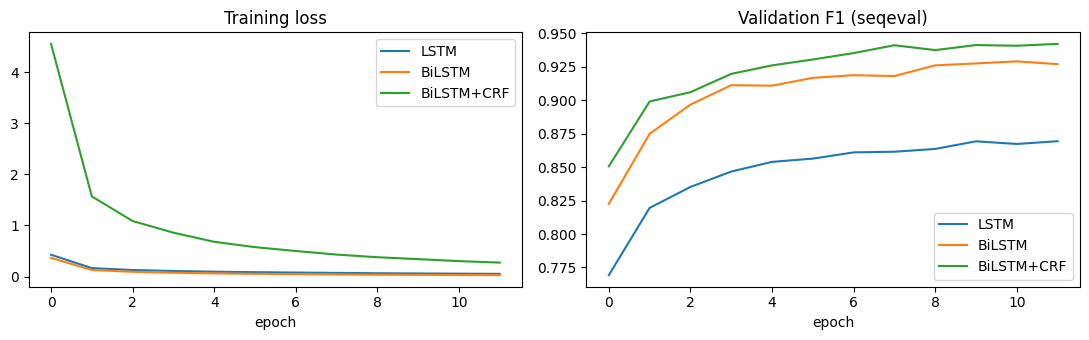

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for n, h in histories.items():
    ax[0].plot([x[0] for x in h], label=n); ax[1].plot([x[1] for x in h], label=n)
ax[0].set_title("Training loss"); ax[1].set_title("Validation F1 (seqeval)")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 5. Fine-tune a transformer (HuggingFace)

In [12]:
from transformers import (AutoTokenizer, AutoModelForTokenClassification, DataCollatorForTokenClassification,
                          TrainingArguments, Trainer)

CKPT = "distilbert-base-cased"      # cased: capitalization is a strong NER signal
tok = AutoTokenizer.from_pretrained(CKPT)

def tokenize_and_align(batch):
    enc = tok(batch["tokens"], truncation=True, is_split_into_words=True)
    all_labels = []
    for i, tags in enumerate(batch["ner_tags"]):
        prev, labels = None, []
        for wid in enc.word_ids(batch_index=i):
            if wid is None: labels.append(-100)            # special tokens
            elif wid != prev: labels.append(tags[wid])     # first sub-token carries the label
            else: labels.append(-100)                      # remaining sub-tokens are ignored
            prev = wid
        all_labels.append(labels)
    enc["labels"] = all_labels
    return enc

tokenized = ds.map(tokenize_and_align, batched=True, remove_columns=ds["train"].column_names)

# alignment demo
ex = ds["train"][12]; e = tok(ex["tokens"], is_split_into_words=True)
print(list(zip(tok.convert_ids_to_tokens(e["input_ids"]), e.word_ids())))

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

[('[CLS]', None), ('Only', 0), ('France', 1), ('and', 2), ('Britain', 3), ('backed', 4), ('Fi', 5), ('##sch', 5), ('##ler', 5), ("'", 6), ('s', 6), ('proposal', 7), ('.', 8), ('[SEP]', None)]


In [13]:
def compute_metrics(p):
    logits, labels = p
    preds = np.argmax(logits, axis=-1)
    yt = [[LABELS[l] for l in lab if l != -100] for lab in labels]
    yp = [[LABELS[pr] for pr, l in zip(pred, lab) if l != -100] for pred, lab in zip(preds, labels)]
    return {"precision": precision_score(yt, yp), "recall": recall_score(yt, yp), "f1": f1_score(yt, yp)}

hf_model = AutoModelForTokenClassification.from_pretrained(
    CKPT, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=L2I)

args = TrainingArguments(
    output_dir="ner_distilbert", num_train_epochs=3, learning_rate=5e-5, weight_decay=0.01,
    per_device_train_batch_size=32, per_device_eval_batch_size=64,
    eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1",
    save_total_limit=1, fp16=torch.cuda.is_available(), report_to="none", seed=SEED)

trainer = Trainer(model=hf_model, args=args, train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
                  data_collator=DataCollatorForTokenClassification(tok), processing_class=tok, compute_metrics=compute_metrics)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  263MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,No log,0.050240,0.911701,0.914002,0.912850
2,0.119036,0.040086,0.931997,0.938741,0.935357
3,0.026229,0.040456,0.934670,0.941434,0.938040


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1317, training_loss=0.0582949222718212, metrics={'train_runtime': 90.6885, 'train_samples_per_second': 464.48, 'train_steps_per_second': 14.522, 'total_flos': 582119704739538.0, 'train_loss': 0.0582949222718212, 'epoch': 3.0})

In [14]:
out = trainer.predict(tokenized["test"])
preds = np.argmax(out.predictions, axis=-1)
hf_true = [[LABELS[l] for l in lab if l != -100] for lab in out.label_ids]
hf_pred = [[LABELS[p] for p, l in zip(pr, lab) if l != -100] for pr, lab in zip(preds, out.label_ids)]

trainer.save_model("ner_model"); tok.save_pretrained("ner_model")   # used by the Gradio app

# keep a copy so the deployment notebook can reload it later (Google Drive + downloadable zip)
import shutil
shutil.make_archive("ner_model", "zip", "ner_model")
try:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copytree("ner_model", "/content/drive/MyDrive/ner_model", dirs_exist_ok=True)
    print("Saved to Google Drive: MyDrive/ner_model")
except Exception as e:
    print("Drive copy skipped:", e)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Drive copy skipped: mount failed


## 6. Evaluation with seqeval (test set)

In [15]:
results = {}
for name, m in models.items():
    results[name] = evaluate(m, loaders["test"])
results["DistilBERT"] = (hf_true, hf_pred)

for name, (yt, yp) in results.items():
    print(f"\n===== {name} =====")
    print(classification_report(yt, yp, digits=4))


===== LSTM =====
              precision    recall  f1-score   support

         LOC     0.7798    0.9131    0.8412      1668
        MISC     0.6326    0.7678    0.6937       702
         ORG     0.7421    0.7104    0.7259      1661
         PER     0.9313    0.9134    0.9223      1617

   micro avg     0.7890    0.8355    0.8116      5648
   macro avg     0.7715    0.8262    0.7958      5648
weighted avg     0.7938    0.8355    0.8122      5648


===== BiLSTM =====
              precision    recall  f1-score   support

         LOC     0.8946    0.9317    0.9128      1668
        MISC     0.7892    0.8105    0.7997       702
         ORG     0.8463    0.8621    0.8542      1661
         PER     0.9558    0.9487    0.9522      1617

   micro avg     0.8843    0.9010    0.8926      5648
   macro avg     0.8715    0.8882    0.8797      5648
weighted avg     0.8848    0.9010    0.8928      5648


===== BiLSTM+CRF =====
              precision    recall  f1-score   support

         LOC 

,Precision,Recall,F1,F1 PER,F1 ORG,F1 LOC,F1 MISC,Invalid I- tags
Model,,,,,,,,
LSTM,0.7890,0.8355,0.8116,0.9223,0.7259,0.8412,0.6937,337
BiLSTM,0.8843,0.9010,0.8926,0.9522,0.8542,0.9128,0.7997,71
BiLSTM+CRF,0.8984,0.8998,0.8991,0.9552,0.8737,0.9108,0.8031,2
DistilBERT,0.8880,0.9055,0.8966,0.9565,0.8670,0.9222,0.7752,82


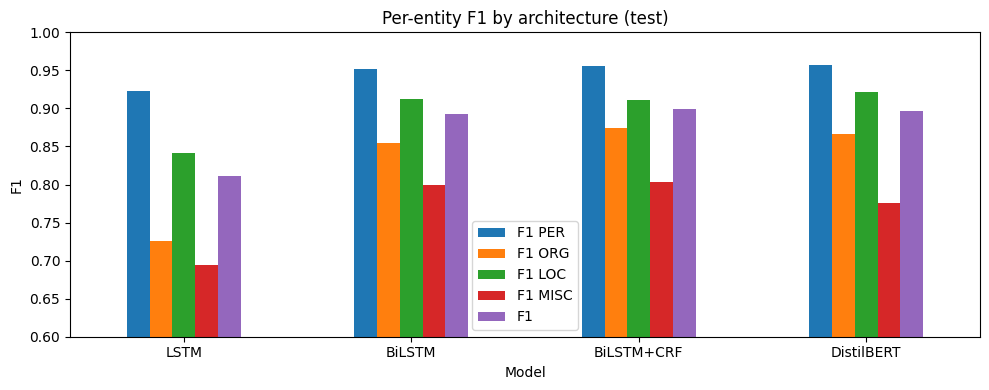

In [16]:
ents = ["PER", "ORG", "LOC", "MISC"]
rows = []
for name, (yt, yp) in results.items():
    rep = classification_report(yt, yp, output_dict=True)
    row = {"Model": name, "Precision": rep["micro avg"]["precision"], "Recall": rep["micro avg"]["recall"], "F1": rep["micro avg"]["f1-score"]}
    for e in ents: row[f"F1 {e}"] = rep[e]["f1-score"]
    row["Invalid I- tags"] = count_invalid(yp)
    rows.append(row)
summary = pd.DataFrame(rows).set_index("Model")
display(summary.style.format({c: "{:.4f}" for c in summary.columns if c != "Invalid I- tags"}).background_gradient(cmap="Greens", subset=["F1"] + [f"F1 {e}" for e in ents]))

summary[[f"F1 {e}" for e in ents] + ["F1"]].plot.bar(figsize=(10, 4), ylim=(0.6, 1.0), title="Per-entity F1 by architecture (test)")
plt.xticks(rotation=0); plt.ylabel("F1"); plt.tight_layout(); plt.show()

## 7. Where does the CRF help? Boundary analysis

In [17]:
from seqeval.metrics.sequence_labeling import get_entities

def boundary_stats(yt, yp):
    """Predicted entities whose type is right but span is wrong (boundary errors), plus exact matches."""
    exact = boundary = 0
    for g, p in zip(yt, yp):
        gs, ps = set(get_entities(g)), set(get_entities(p))
        exact += len(gs & ps)
        for (t, s, e) in ps - gs:
            if any(gt == t and not (e < gs_ or s > ge) for gt, gs_, ge in gs): boundary += 1
    return exact, boundary

rows = []
for name, (yt, yp) in results.items():
    ex_, bd = boundary_stats(yt, yp)
    rows.append({"Model": name, "Invalid I- tags": count_invalid(yp), "Exact-match entities": ex_, "Same-type boundary errors": bd})
display(pd.DataFrame(rows).set_index("Model"))

# sentences where BiLSTM is wrong and BiLSTM+CRF is right
tokens = data["test"]["tokens"]; yt = results["BiLSTM"][0]
shown = 0
for i in range(len(tokens)):
    a, b = results["BiLSTM"][1][i], results["BiLSTM+CRF"][1][i]
    if a != yt[i] and b == yt[i] and shown < 4:
        shown += 1
        print(" ".join(tokens[i]))
        print("  gold      :", [(w, t) for w, t in zip(tokens[i], yt[i]) if t != "O"])
        print("  BiLSTM    :", [(w, t) for w, t in zip(tokens[i], a) if t != "O"])
        print("  BiLSTM+CRF:", [(w, t) for w, t in zip(tokens[i], b) if t != "O"], "\n")

,Invalid I- tags,Exact-match entities,Same-type boundary errors
Model,,,
LSTM,337,4719,351
BiLSTM,71,5089,148
BiLSTM+CRF,2,5082,91
DistilBERT,82,5114,126


SOCCER - ENGLISH F.A. CUP SECOND ROUND RESULT .
  gold      : [('ENGLISH', 'B-MISC'), ('F.A.', 'I-MISC'), ('CUP', 'I-MISC')]
  BiLSTM    : [('ENGLISH', 'B-MISC'), ('CUP', 'I-MISC')]
  BiLSTM+CRF: [('ENGLISH', 'B-MISC'), ('F.A.', 'I-MISC'), ('CUP', 'I-MISC')] 

FIFA 's players ' status committee , meeting in Barcelona , decided that although the Udinese document was basically valid , it could not be legally protected .
  gold      : [('FIFA', 'B-ORG'), ('Barcelona', 'B-LOC'), ('Udinese', 'B-ORG')]
  BiLSTM    : [('FIFA', 'B-ORG'), ('Barcelona', 'B-ORG'), ('Udinese', 'B-ORG')]
  BiLSTM+CRF: [('FIFA', 'B-ORG'), ('Barcelona', 'B-LOC'), ('Udinese', 'B-ORG')] 

Score on the first day of the four-day Sheffield Shield match between Tasmania and Victoria at Bellerive Oval on Friday :
  gold      : [('Sheffield', 'B-MISC'), ('Shield', 'I-MISC'), ('Tasmania', 'B-LOC'), ('Victoria', 'B-LOC'), ('Bellerive', 'B-LOC'), ('Oval', 'I-LOC')]
  BiLSTM    : [('Sheffield', 'B-ORG'), ('Shield', 'I-MISC'), ('

### Comparison and discussion
*(Read the numbers from the tables above; the pattern below is what to expect and what to confirm in your run.)*

* **LSTM → BiLSTM:** a unidirectional LSTM only sees left context. Words such as "Washington" or "Jordan" need the right context to decide between PER, ORG and LOC, so the BiLSTM gains clearly, especially on ORG and LOC.
* **BiLSTM → BiLSTM+CRF:** the softmax layer labels every token independently, so it can emit illegal sequences such as `O I-ORG` or `B-PER I-LOC`. The CRF learns transition scores (for example `I-PER` is very unlikely after `O` or `B-LOC`) and decodes the best whole sequence with Viterbi. This lowers the "Invalid I- tags" count and the boundary errors in the table above, which shows up as better precision and entity-level F1, mostly for multi-token entities.
* **Transformer:** the pre-trained contextual representation of DistilBERT usually gives the highest F1, with the biggest gain on MISC and ORG, which depend most on world knowledge. The cost is larger model size and slower inference.
* **MISC** is the hardest class for all models because it is a heterogeneous bucket (nationalities, events, titles).

## 8. Real-time color-coded visualization
Inline preview in the notebook with the fine-tuned model. The same function powers the Gradio app.

In [18]:
from transformers import pipeline
from IPython.display import HTML, display

ner = pipeline("token-classification", model="ner_model", tokenizer="ner_model",
               aggregation_strategy="simple", device=0 if torch.cuda.is_available() else -1)

COLORS = {"PER": "#f9a8d4", "ORG": "#93c5fd", "LOC": "#86efac", "MISC": "#fde047"}

def to_segments(text):
    """Split text into [(chunk, label_or_None)] using the model's entity spans."""
    segs, pos = [], 0
    for e in sorted(ner(text), key=lambda x: x["start"]):
        if e["start"] > pos: segs.append((text[pos:e["start"]], None))
        segs.append((text[e["start"]:e["end"]], e["entity_group"])); pos = e["end"]
    if pos < len(text): segs.append((text[pos:], None))
    return segs

def show(text):
    html = "".join(
        s if l is None else
        f'<mark style="background:{COLORS.get(l, "#ddd")};padding:2px 6px;border-radius:6px;margin:0 2px">{s}'
        f'<sub style="font-size:.65em;font-weight:700;margin-left:4px">{l}</sub></mark>'
        for s, l in to_segments(text))
    legend = " ".join(f'<mark style="background:{c};padding:2px 8px;border-radius:6px">{k}</mark>' for k, c in COLORS.items())
    display(HTML(f'<div style="font-size:1.05em;line-height:2">{html}</div><div style="margin-top:8px">{legend}</div>'))

show("Sundar Pichai said Google will open a new office in Cairo, Egypt, next to the Nile and the American University in Cairo.")
show("Angela Merkel met Emmanuel Macron in Berlin to discuss the European Union budget.")

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

## 9. Deployment: Gradio app

In [ ]:
import gradio as gr

def predict(text):
    return to_segments(text) if text.strip() else []

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=5, label="Enter text", placeholder="Type or paste any English text..."),
    outputs=gr.HighlightedText(label="Detected entities", combine_adjacent=False, show_legend=True, color_map=COLORS),
    examples=[["Elon Musk visited Berlin to meet Volkswagen executives."],
              ["The United Nations headquarters in New York hosted the French delegation."],
              ["Mohamed Salah plays for Liverpool and was born in Nagrig, Egypt."]],
    title="Named Entity Recognition",
    description="Fine-tuned DistilBERT on CoNLL-2003. Highlights PER, ORG, LOC and MISC entities.",
    flagging_mode="never", live=True)

demo.launch(share=True, debug=True)   # keep this cell running; open the public link

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://3348d381fb782c8ebd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
